# Auditoría de los datos WAP utilizados por SAN

Este notebook audita los datos ubicados en `data/WAP`, mencionados como fuente de datos en el repositorio de SAN.

## Objetivos

1. Verificar la correspondencia entre los *captions* y las imágenes comprimidas de WAP.
2. Detectar imágenes duplicadas dentro del entrenamiento WAP.
3. Comprobar posibles solapamientos exactos entre el entrenamiento WAP y CROHME 2016.
4. Comprobar posibles solapamientos exactos entre el entrenamiento WAP y CROHME 2019.
5. Buscar candidatos visualmente cercanos para revisión manual.
6. Mantener separadas las coincidencias de *ground truth*, porque una expresión repetida no implica que sea la misma instancia.

Los archivos `.tar.gz` se leen directamente; no se extraen ni se modifican.

## Fuentes comparadas

| Fuente | Ubicación | Uso en la auditoría |
|---|---|---|
| Entrenamiento WAP | `data/WAP/off_image_train.tar.gz` | Conjunto auditado |
| Anotaciones WAP train | `data/WAP/train_caption.txt` | Ground truth del entrenamiento |
| Test WAP 2014 | `data/WAP/off_image_test.tar.gz` | Inventario y referencia auxiliar |
| Test WAP 2016 | `data/WAP/16 (1).tar.gz` | Comparación directa con train |
| CROHME 2016 del proyecto | `data/Modelo2/2016` | Verificación independiente y anotaciones |
| CROHME 2019 del proyecto | `data/Modelo2/2019` | Verificación contra el segundo test final |

WAP no contiene en esta carpeta un archivo propio para CROHME 2019. Por ello se utiliza la distribución 2019 de PosFormer, que forma parte de los datos del proyecto.

La auditoría es descriptiva: no entrena modelos ni ajusta parámetros o umbrales con CROHME 2016/2019.

## 1. Importaciones y configuración

In [1]:
# Librerías estándar para archivos comprimidos, hashes y rutas.
from pathlib import Path
from io import BytesIO
import hashlib
import json
import tarfile

# Librerías para análisis tabular, imágenes y visualización.
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Parámetros diagnósticos fijos; no son parámetros del modelo.
UMBRAL_HAMMING_DHASH = 4
MAX_CANDIDATOS_POR_IMAGEN_TEST = 3
MAX_CANDIDATOS_A_VISUALIZAR = 20
SEMILLA = 42
REMUESTREO_LANCZOS = (
    Image.Resampling.LANCZOS
    if hasattr(Image, "Resampling")
    else Image.LANCZOS
)

pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_rows", 100)

## 2. Localización y rutas

El notebook comprueba las fuentes WAP y los tests 2016/2019 antes de comenzar.

In [2]:
# Localiza la raíz mediante archivos representativos de WAP y Modelo2.
def localizar_raiz(inicio=None):
    inicio = Path.cwd() if inicio is None else Path(inicio)
    inicio = inicio.resolve()
    for raiz in [inicio, *inicio.parents]:
        requeridos = [
            raiz / "data" / "WAP" / "off_image_train.tar.gz",
            raiz / "data" / "WAP" / "train_caption.txt",
            raiz / "data" / "WAP" / "16 (1).tar.gz",
            raiz / "data" / "Modelo2" / "2016" / "caption.txt",
            raiz / "data" / "Modelo2" / "2019" / "caption.txt",
        ]
        if all(ruta.is_file() for ruta in requeridos):
            return raiz
    raise FileNotFoundError("No se encontraron todas las fuentes requeridas.")

RAIZ = localizar_raiz()
WAP_DIR = RAIZ / "data" / "WAP"
MODELO2_DIR = RAIZ / "data" / "Modelo2"
RESULTADOS_DIR = RAIZ / "Cascada" / "00_analisis_exploratorio" / "resultados"

WAP_TRAIN_TAR = WAP_DIR / "off_image_train.tar.gz"
WAP_2014_TAR = WAP_DIR / "off_image_test.tar.gz"
WAP_2016_TAR = WAP_DIR / "16 (1).tar.gz"
WAP_TRAIN_CAPTION = WAP_DIR / "train_caption.txt"
WAP_2014_CAPTION = WAP_DIR / "test_caption.txt"

M2_2016_DIR = MODELO2_DIR / "2016"
M2_2019_DIR = MODELO2_DIR / "2019"

print(f"Raíz: {RAIZ}")
for ruta in [
    WAP_TRAIN_TAR, WAP_2014_TAR, WAP_2016_TAR,
    WAP_TRAIN_CAPTION, WAP_2014_CAPTION,
    M2_2016_DIR, M2_2019_DIR,
]:
    print(f"{ruta.relative_to(RAIZ)} | existe={ruta.exists()}")

Raíz: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas
data/WAP/off_image_train.tar.gz | existe=True
data/WAP/off_image_test.tar.gz | existe=True
data/WAP/16 (1).tar.gz | existe=True
data/WAP/train_caption.txt | existe=True
data/WAP/test_caption.txt | existe=True
data/Modelo2/2016 | existe=True
data/Modelo2/2019 | existe=True


## 3. Lectura de captions e índices de archivos comprimidos

Los BMP de WAP terminan en `_0.bmp`. Ese sufijo técnico se retira únicamente para recuperar el identificador canónico usado por los archivos de anotaciones.

In [3]:
# Lee anotaciones tabuladas y rechaza IDs duplicados.
def leer_caption(ruta, particion):
    registros = []
    errores = []
    with ruta.open("r", encoding="utf-8-sig") as archivo:
        for numero_linea, linea_cruda in enumerate(archivo, start=1):
            linea = linea_cruda.rstrip("\r\n")
            if not linea.strip():
                errores.append(
                    {"particion": particion, "linea": numero_linea, "motivo": "vacía"}
                )
                continue
            if "\t" not in linea:
                errores.append(
                    {
                        "particion": particion,
                        "linea": numero_linea,
                        "motivo": "sin tabulador",
                    }
                )
                continue
            identificador, latex = linea.split("\t", maxsplit=1)
            registros.append(
                {
                    "particion": particion,
                    "orden_caption": len(registros),
                    "linea_caption": numero_linea,
                    "id": identificador.strip(),
                    "latex": latex.strip(),
                }
            )

    tabla = pd.DataFrame(registros)
    if tabla["id"].duplicated().any():
        ids = tabla.loc[tabla["id"].duplicated(keep=False), "id"].tolist()
        raise ValueError(f"IDs duplicados en {particion}: {ids[:10]}")
    return tabla, pd.DataFrame(errores)

# Convierte un nombre interno del tar en el ID usado en caption.txt.
def id_canonico_wap(nombre_miembro):
    nombre = Path(nombre_miembro).stem
    return nombre[:-2] if nombre.endswith("_0") else nombre

# Construye un índice sin extraer archivos al disco.
def indexar_tar_imagenes(ruta_tar, particion):
    registros = []
    with tarfile.open(ruta_tar, mode="r:gz") as archivo_tar:
        for miembro in archivo_tar.getmembers():
            if not miembro.isfile():
                continue
            if Path(miembro.name).suffix.lower() != ".bmp":
                continue
            registros.append(
                {
                    "particion": particion,
                    "id": id_canonico_wap(miembro.name),
                    "miembro_tar": miembro.name,
                    "bytes_declarados": miembro.size,
                    "ruta_tar": str(ruta_tar),
                }
            )

    tabla = pd.DataFrame(registros)
    if tabla["id"].duplicated().any():
        ids = tabla.loc[tabla["id"].duplicated(keep=False), "id"].tolist()
        raise ValueError(f"IDs de imagen duplicados en {particion}: {ids[:10]}")
    return tabla

caption_wap_train, errores_wap_train = leer_caption(
    WAP_TRAIN_CAPTION, "wap_train"
)
caption_wap_2014, errores_wap_2014 = leer_caption(
    WAP_2014_CAPTION, "wap_2014"
)

imagenes_wap_train = indexar_tar_imagenes(WAP_TRAIN_TAR, "wap_train")
imagenes_wap_2014 = indexar_tar_imagenes(WAP_2014_TAR, "wap_2014")
imagenes_wap_2016 = indexar_tar_imagenes(WAP_2016_TAR, "wap_2016")

display(
    pd.DataFrame(
        {
            "caption": [
                len(caption_wap_train),
                len(caption_wap_2014),
                np.nan,
            ],
            "imagenes_tar": [
                len(imagenes_wap_train),
                len(imagenes_wap_2014),
                len(imagenes_wap_2016),
            ],
            "errores_caption": [
                len(errores_wap_train),
                len(errores_wap_2014),
                np.nan,
            ],
        },
        index=["wap_train", "wap_2014", "wap_2016"],
    )
)

,caption,imagenes_tar,errores_caption
wap_train,8835.0,8835,0.0
wap_2014,986.0,986,0.0
wap_2016,NaN,1147,NaN


## 4. Correspondencia del inventario WAP

WAP 2016 no incluye un caption separado dentro de `data/WAP`; sus IDs se contrastarán después con el caption de CROHME 2016 disponible en `data/Modelo2/2016`.

In [4]:
# Comprueba correspondencia train y test 2014 de WAP por ID.
def resumir_correspondencia(caption, imagenes, nombre):
    ids_caption = set(caption["id"])
    ids_imagen = set(imagenes["id"])
    return {
        "particion": nombre,
        "caption": len(caption),
        "imagenes": len(imagenes),
        "caption_sin_imagen": len(ids_caption - ids_imagen),
        "imagen_sin_caption": len(ids_imagen - ids_caption),
    }

df_correspondencia = pd.DataFrame(
    [
        resumir_correspondencia(
            caption_wap_train, imagenes_wap_train, "wap_train"
        ),
        resumir_correspondencia(
            caption_wap_2014, imagenes_wap_2014, "wap_2014"
        ),
    ]
).set_index("particion")
display(df_correspondencia)

if df_correspondencia[
    ["caption_sin_imagen", "imagen_sin_caption"]
].to_numpy().sum() != 0:
    raise ValueError("Existen discrepancias entre captions e imágenes WAP.")

# Une el ground truth al inventario de entrenamiento.
wap_train = imagenes_wap_train.merge(
    caption_wap_train[["id", "latex"]],
    on="id",
    how="left",
    validate="one_to_one",
)

,caption,imagenes,caption_sin_imagen,imagen_sin_caption
particion,,,,
wap_train,8835,8835,0,0
wap_2014,986,986,0,0


## 5. Funciones para leer y caracterizar imágenes sin extraerlas

Para cada BMP se calculan:

- SHA-256 del archivo completo;
- SHA-256 de dimensiones y píxeles en escala de grises;
- dimensiones;
- dHash perceptual de 64 bits.

In [5]:
# Lee los bytes de un miembro concreto sin escribirlo en el sistema de archivos.
def leer_bytes_tar(ruta_tar, miembro_tar):
    with tarfile.open(ruta_tar, mode="r:gz") as archivo_tar:
        extraido = archivo_tar.extractfile(miembro_tar)
        if extraido is None:
            raise FileNotFoundError(f"No se pudo leer {miembro_tar}")
        return extraido.read()

def caracterizar_bytes_imagen(datos):
    hash_archivo = hashlib.sha256(datos).hexdigest()

    with Image.open(BytesIO(datos)) as imagen:
        modo = imagen.mode
        ancho, alto = imagen.size
        gris_pil = imagen.convert("L")
        gris = np.asarray(gris_pil, dtype=np.uint8)
        pequena = gris_pil.resize((9, 8), REMUESTREO_LANCZOS)
        matriz_pequena = np.asarray(pequena, dtype=np.uint8)

    digest_pixeles = hashlib.sha256()
    digest_pixeles.update(np.asarray(gris.shape, dtype=np.int64).tobytes())
    digest_pixeles.update(gris.tobytes())

    diferencias = matriz_pequena[:, 1:] > matriz_pequena[:, :-1]
    dhash = 0
    for bit in diferencias.ravel():
        dhash = (dhash << 1) | int(bit)

    return {
        "ancho": ancho,
        "alto": alto,
        "modo": modo,
        "sha256_archivo": hash_archivo,
        "sha256_pixeles": digest_pixeles.hexdigest(),
        "dhash64": np.uint64(dhash),
    }

def caracterizar_tar(ruta_tar, indice):
    # Abre el tar una sola vez para evitar el costo de reabrirlo por imagen.
    registros = []
    with tarfile.open(ruta_tar, mode="r:gz") as archivo_tar:
        for _, fila in indice.iterrows():
            extraido = archivo_tar.extractfile(fila["miembro_tar"])
            if extraido is None:
                raise FileNotFoundError(fila["miembro_tar"])
            caracteristicas = caracterizar_bytes_imagen(extraido.read())
            registros.append({**fila.to_dict(), **caracteristicas})
    return pd.DataFrame(registros)

def caracterizar_archivo(ruta):
    datos = Path(ruta).read_bytes()
    return caracterizar_bytes_imagen(datos)

## 6. Caracterización del entrenamiento y tests WAP

Esta es una de las celdas más costosas: lee cada imagen comprimida para calcular sus huellas. No extrae archivos.

In [6]:
# Caracteriza train, 2014 y 2016 de WAP.
wap_train_img = caracterizar_tar(WAP_TRAIN_TAR, imagenes_wap_train)
wap_2014_img = caracterizar_tar(WAP_2014_TAR, imagenes_wap_2014)
wap_2016_img = caracterizar_tar(WAP_2016_TAR, imagenes_wap_2016)

# Reincorpora el ground truth del entrenamiento tras calcular las huellas.
wap_train = wap_train_img.merge(
    caption_wap_train[["id", "latex"]],
    on="id",
    how="left",
    validate="one_to_one",
)

resumen_hashes_wap = pd.DataFrame(
    {
        "muestras": {
            "wap_train": len(wap_train),
            "wap_2014": len(wap_2014_img),
            "wap_2016": len(wap_2016_img),
        },
        "hashes_archivo_unicos": {
            "wap_train": wap_train["sha256_archivo"].nunique(),
            "wap_2014": wap_2014_img["sha256_archivo"].nunique(),
            "wap_2016": wap_2016_img["sha256_archivo"].nunique(),
        },
        "hashes_pixeles_unicos": {
            "wap_train": wap_train["sha256_pixeles"].nunique(),
            "wap_2014": wap_2014_img["sha256_pixeles"].nunique(),
            "wap_2016": wap_2016_img["sha256_pixeles"].nunique(),
        },
    }
)
display(resumen_hashes_wap)

,muestras,hashes_archivo_unicos,hashes_pixeles_unicos
wap_train,8835,8793,8793
wap_2014,986,985,985
wap_2016,1147,1147,1147


## 7. Duplicados internos del entrenamiento WAP

Se distingue el número total de archivos del número de contenidos únicos. Cada grupo duplicado conserva sus IDs, ground truth y dimensiones para verificar si una misma imagen fue asociada con anotaciones diferentes.

In [7]:
# Agrupa por píxeles exactos para describir copias y posibles recodificaciones.
duplicados_wap_train = (
    wap_train.groupby("sha256_pixeles")
    .agg(
        n_archivos=("id", "size"),
        n_ids=("id", "nunique"),
        n_ground_truth=("latex", "nunique"),
        n_hashes_archivo=("sha256_archivo", "nunique"),
        ids=("id", lambda s: list(s)),
        ground_truth=("latex", lambda s: sorted(set(s))),
        dimensiones=(
            "ancho",
            lambda s: sorted(set(zip(s, wap_train.loc[s.index, "alto"]))),
        ),
    )
    .reset_index()
)
duplicados_wap_train = duplicados_wap_train[
    duplicados_wap_train["n_archivos"] > 1
].sort_values(["n_archivos", "sha256_pixeles"], ascending=[False, True])

resumen_duplicados_wap = pd.Series(
    {
        "archivos_train": len(wap_train),
        "contenidos_de_pixeles_unicos": wap_train["sha256_pixeles"].nunique(),
        "grupos_duplicados": len(duplicados_wap_train),
        "archivos_en_grupos_duplicados": int(
            duplicados_wap_train["n_archivos"].sum()
        ),
        "copias_adicionales": int(
            (duplicados_wap_train["n_archivos"] - 1).sum()
        ),
        "grupos_con_ground_truth_distinto": int(
            duplicados_wap_train["n_ground_truth"].gt(1).sum()
        ),
        "grupos_recodificados": int(
            duplicados_wap_train["n_hashes_archivo"].gt(1).sum()
        ),
    },
    name="cantidad",
)
display(resumen_duplicados_wap.to_frame())
display(duplicados_wap_train.head(100))

,cantidad
archivos_train,8835
contenidos_de_pixeles_unicos,8793
grupos_duplicados,42
archivos_en_grupos_duplicados,84
copias_adicionales,42
grupos_con_ground_truth_distinto,0
grupos_recodificados,0


,sha256_pixeles,n_archivos,n_ids,n_ground_truth,n_hashes_archivo,ids,ground_truth,dimensiones
75,02237893f982f1de9b1e003301ef0d12636eadf92d5824cfeceea3808fbf6b89,2,2,1,1,"[TrainData2_22_sub_95, KME2G3_24_sub_95]",[\sqrt { 1 + \sqrt { 2 + \sqrt { 3 + \sqrt { 4 } } } }],"[(263, 94)]"
128,03a83a5d5832ac180db8e3a45460d3d1e34e3e6a431f2ad6194917fe94b6d51e,2,2,1,1,"[KME2G3_10_sub_95, TrainData2_8_sub_95]",[\sqrt { 1 + \sqrt { 2 + \sqrt { 3 + \sqrt { 4 } } } }],"[(296, 114)]"
235,06faa75097274b34f57d69f039240e732df542d7f43208c5891c391acf8d5966,2,2,1,1,"[TrainData1_8_sub_21, KME1G3_11_sub_21]",[A = \sqrt { a + \frac { 1 } { \sqrt { a + \frac { 1 } { \sqrt { a } } } } } + \sqrt { b }],"[(403, 144)]"
661,12ccb486442dc61acd26469f132a30a53c78917e5cb2c479696cb841524c494d,2,2,1,1,"[TrainData1_4_sub_21, KME1G3_5_sub_21]",[A = \sqrt { a + \frac { 1 } { \sqrt { a + \frac { 1 } { \sqrt { a } } } } } + \sqrt { b }],"[(313, 123)]"
883,18e0b03b8639ab31f51ac57c47d077bbbb80c57144f3e9165676a9e6138f10fc,2,2,1,1,"[TrainData2_7_sub_95, KME2G3_9_sub_95]",[\sqrt { 1 + \sqrt { 2 + \sqrt { 3 + \sqrt { 4 } } } }],"[(287, 86)]"
912,199f07006ea32bdf9691403046677ed8a028ef97c0008a22b71c6cebf901c981,2,2,1,1,"[TrainData1_3_sub_21, KME1G3_4_sub_21]",[A = \sqrt { a + \frac { 1 } { \sqrt { a + \frac { 1 } { \sqrt { a } } } } } + \sqrt { b }],"[(354, 123)]"
1239,246665860d4cb8cf86a165455ffb0aa3ef605d49ba6adb5e26766d140fbeaaba,2,2,1,1,"[TrainData2_3_sub_95, KME2G3_3_sub_95]",[\sqrt { 1 + \sqrt { 2 + \sqrt { 3 + \sqrt { 4 } } } }],"[(290, 104)]"
1576,2e7c8f8524c50edb429000ed6f6b9eab79dd9f1cf9cdd4057fa7d3f3bc112713,2,2,1,1,"[KME2G3_25_sub_95, TrainData2_23_sub_95]",[\sqrt { 1 + \sqrt { 2 + \sqrt { 3 + \sqrt { 4 } } } }],"[(389, 119)]"
1933,392be0f8d1862639bb2260c2fac63596a149e390c2ea9539e1bde9c2db2b4766,2,2,1,1,"[TrainData2_0_sub_95, KME2G3_0_sub_95]",[\sqrt { 1 + \sqrt { 2 + \sqrt { 3 + \sqrt { 4 } } } }],"[(327, 105)]"
2078,3d7e79cf93ff200948ef7a42ee0bc1a27682a5e5e901dda2611ab685365f0016,2,2,1,1,"[TrainData2_14_sub_95, KME2G3_16_sub_95]",[\sqrt { 1 + \sqrt { 2 + \sqrt { 3 + \sqrt { 4 } } } }],"[(266, 108)]"


## 8. Carga de CROHME 2016 y 2019 del proyecto

Estas copias aportan el test 2019 que no está presente en `data/WAP` y los captions de 2016/2019.

In [8]:
# Carga captions e imágenes de las distribuciones de PosFormer.
def cargar_test_modelo2(directorio, anio):
    caption, errores = leer_caption(
        directorio / "caption.txt",
        f"modelo2_{anio}",
    )
    imagenes = sorted((directorio / "img").glob("*.bmp"))
    mapa = {ruta.stem: ruta for ruta in imagenes}

    if len(mapa) != len(imagenes):
        raise ValueError(f"Nombres de imagen duplicados en Modelo2/{anio}")

    caption["ruta_imagen"] = caption["id"].map(mapa)
    if len(errores) or caption["ruta_imagen"].isna().any():
        raise ValueError(f"Inventario incompleto en Modelo2/{anio}")

    caracteristicas = pd.DataFrame(
        [caracterizar_archivo(ruta) for ruta in caption["ruta_imagen"]]
    )
    return pd.concat(
        [caption.reset_index(drop=True), caracteristicas],
        axis=1,
    )

modelo2_2016 = cargar_test_modelo2(M2_2016_DIR, "2016")
modelo2_2019 = cargar_test_modelo2(M2_2019_DIR, "2019")

display(
    pd.DataFrame(
        {
            "muestras": {
                "modelo2_2016": len(modelo2_2016),
                "modelo2_2019": len(modelo2_2019),
            },
            "hashes_archivo_unicos": {
                "modelo2_2016": modelo2_2016["sha256_archivo"].nunique(),
                "modelo2_2019": modelo2_2019["sha256_archivo"].nunique(),
            },
            "hashes_pixeles_unicos": {
                "modelo2_2016": modelo2_2016["sha256_pixeles"].nunique(),
                "modelo2_2019": modelo2_2019["sha256_pixeles"].nunique(),
            },
        }
    )
)

,muestras,hashes_archivo_unicos,hashes_pixeles_unicos
modelo2_2016,1147,1147,1147
modelo2_2019,1199,1199,1199


## 9. Correspondencia entre el archivo WAP 2016 y Modelo2/2016

Esta comprobación permite saber si ambas fuentes representan las mismas instancias de CROHME 2016, aunque los BMP o sus nombres tengan otra convención.

In [9]:
# Cruza WAP 2016 y Modelo2 2016 por ID y compara sus huellas.
comparacion_fuentes_2016 = wap_2016_img.merge(
    modelo2_2016[
        [
            "id", "latex", "ruta_imagen", "sha256_archivo",
            "sha256_pixeles", "ancho", "alto",
        ]
    ],
    on="id",
    how="outer",
    suffixes=("_wap", "_modelo2"),
    indicator=True,
    validate="one_to_one",
)

comparacion_fuentes_2016["archivo_igual"] = (
    comparacion_fuentes_2016["sha256_archivo_wap"]
    == comparacion_fuentes_2016["sha256_archivo_modelo2"]
)
comparacion_fuentes_2016["pixeles_iguales"] = (
    comparacion_fuentes_2016["sha256_pixeles_wap"]
    == comparacion_fuentes_2016["sha256_pixeles_modelo2"]
)

display(
    pd.Series(
        {
            "IDs en ambas fuentes": int(
                comparacion_fuentes_2016["_merge"].eq("both").sum()
            ),
            "solo WAP": int(
                comparacion_fuentes_2016["_merge"].eq("left_only").sum()
            ),
            "solo Modelo2": int(
                comparacion_fuentes_2016["_merge"].eq("right_only").sum()
            ),
            "archivos idénticos": int(
                comparacion_fuentes_2016["archivo_igual"].fillna(False).sum()
            ),
            "píxeles idénticos": int(
                comparacion_fuentes_2016["pixeles_iguales"].fillna(False).sum()
            ),
        },
        name="cantidad",
    ).to_frame()
)

,cantidad
IDs en ambas fuentes,1147
solo WAP,0
solo Modelo2,0
archivos idénticos,1147
píxeles idénticos,1147


## 10. Solapamientos exactos del entrenamiento WAP

Se comparan IDs, archivos y píxeles contra:

- WAP 2016, leído desde el archivo comprimido;
- Modelo2/2016, como verificación independiente;
- Modelo2/2019, porque WAP no contiene un archivo 2019 en esta carpeta.

In [10]:
# Cruza dos tablas por una huella y conserva información trazable.
def cruzar_hash(train, test, columna_hash, etiqueta_test):
    izquierda = train[
        ["id", "latex", "miembro_tar", "ancho", "alto", columna_hash]
    ].rename(
        columns={
            "id": "id_train",
            "latex": "latex_train",
            "miembro_tar": "imagen_train",
            "ancho": "ancho_train",
            "alto": "alto_train",
        }
    )

    columnas_test = ["id", "ancho", "alto", columna_hash]
    if "latex" in test.columns:
        columnas_test.append("latex")
    if "ruta_imagen" in test.columns:
        columnas_test.append("ruta_imagen")
    if "miembro_tar" in test.columns:
        columnas_test.append("miembro_tar")

    derecha = test[columnas_test].copy().rename(
        columns={
            "id": f"id_{etiqueta_test}",
            "latex": f"latex_{etiqueta_test}",
            "ruta_imagen": f"imagen_{etiqueta_test}",
            "miembro_tar": f"imagen_{etiqueta_test}",
            "ancho": f"ancho_{etiqueta_test}",
            "alto": f"alto_{etiqueta_test}",
        }
    )

    return izquierda.merge(
        derecha,
        on=columna_hash,
        how="inner",
        validate="many_to_many",
    )

objetivos = {
    "wap_2016": wap_2016_img,
    "modelo2_2016": modelo2_2016,
    "modelo2_2019": modelo2_2019,
}

solapamientos_exactos = {}
ids_compartidos = {}

for nombre, test in objetivos.items():
    ids_compartidos[nombre] = sorted(set(wap_train["id"]) & set(test["id"]))
    solapamientos_exactos[(nombre, "archivo")] = cruzar_hash(
        wap_train, test, "sha256_archivo", nombre
    )
    solapamientos_exactos[(nombre, "pixeles")] = cruzar_hash(
        wap_train, test, "sha256_pixeles", nombre
    )

    print(f"\nTrain WAP vs. {nombre}")
    print(f"  IDs compartidos: {len(ids_compartidos[nombre])}")
    print(
        "  Pares de archivo exacto: "
        f"{len(solapamientos_exactos[(nombre, 'archivo')])}"
    )
    print(
        "  Pares de píxeles exactos: "
        f"{len(solapamientos_exactos[(nombre, 'pixeles')])}"
    )
    display(solapamientos_exactos[(nombre, "pixeles")].head(100))


Train WAP vs. wap_2016
  IDs compartidos: 0
  Pares de archivo exacto: 0
  Pares de píxeles exactos: 0


,id_train,latex_train,imagen_train,ancho_train,alto_train,sha256_pixeles,id_wap_2016,ancho_wap_2016,alto_wap_2016,imagen_wap_2016



Train WAP vs. modelo2_2016
  IDs compartidos: 0
  Pares de archivo exacto: 0
  Pares de píxeles exactos: 0


,id_train,latex_train,imagen_train,ancho_train,alto_train,sha256_pixeles,id_modelo2_2016,ancho_modelo2_2016,alto_modelo2_2016,latex_modelo2_2016,imagen_modelo2_2016



Train WAP vs. modelo2_2019
  IDs compartidos: 0
  Pares de archivo exacto: 0
  Pares de píxeles exactos: 0


,id_train,latex_train,imagen_train,ancho_train,alto_train,sha256_pixeles,id_modelo2_2019,ancho_modelo2_2019,alto_modelo2_2019,latex_modelo2_2019,imagen_modelo2_2019


## 11. Comparación auxiliar de ground truth

Solo se aplica a los tests con anotaciones disponibles. Compartir LaTeX no constituye evidencia de que la imagen sea la misma.

In [11]:
# Normaliza exclusivamente \limits para una comparación auxiliar.
def normalizar_limits(secuencia):
    return " ".join(
        token for token in str(secuencia).split()
        if token != r"\limits"
    )

wap_train["latex_sin_limits"] = wap_train["latex"].map(normalizar_limits)
for tabla in [modelo2_2016, modelo2_2019]:
    tabla["latex_sin_limits"] = tabla["latex"].map(normalizar_limits)

filas_ground_truth = []
for anio, test in [("2016", modelo2_2016), ("2019", modelo2_2019)]:
    filas_ground_truth.append(
        {
            "test": anio,
            "referencias_unicas_compartidas": len(
                set(wap_train["latex"]) & set(test["latex"])
            ),
            "muestras_test_con_latex_en_train": int(
                test["latex"].isin(set(wap_train["latex"])).sum()
            ),
            "referencias_unicas_compartidas_sin_limits": len(
                set(wap_train["latex_sin_limits"])
                & set(test["latex_sin_limits"])
            ),
            "muestras_test_con_latex_sin_limits_en_train": int(
                test["latex_sin_limits"].isin(
                    set(wap_train["latex_sin_limits"])
                ).sum()
            ),
        }
    )

df_ground_truth = pd.DataFrame(filas_ground_truth).set_index("test")
display(df_ground_truth)
print("Mismo ground truth no significa misma instancia manuscrita.")

,referencias_unicas_compartidas,muestras_test_con_latex_en_train,referencias_unicas_compartidas_sin_limits,muestras_test_con_latex_sin_limits_en_train
test,,,,
2016,18,20,18,20
2019,3,4,3,4


Mismo ground truth no significa misma instancia manuscrita.


## 12. Candidatos perceptuales

dHash reduce cada imagen a una huella de 64 bits. Los pares con distancia de Hamming menor o igual que cuatro se consideran candidatos para revisión, no coincidencias demostradas.

In [12]:
# Tabla para contar bits en los bytes de un uint64.
CONTEO_BITS_BYTE = np.array(
    [bin(valor).count("1") for valor in range(256)],
    dtype=np.uint8,
)

def distancias_hamming_vector(hash_referencia, hashes):
    xor = np.bitwise_xor(hashes, np.uint64(hash_referencia))
    bytes_xor = xor.view(np.uint8).reshape(-1, 8)
    return CONTEO_BITS_BYTE[bytes_xor].sum(axis=1)

def buscar_candidatos(train, test, etiqueta_test):
    hashes_train = train["dhash64"].to_numpy(dtype=np.uint64)
    registros = []

    for _, muestra_test in test.iterrows():
        distancias = distancias_hamming_vector(
            muestra_test["dhash64"],
            hashes_train,
        )
        indices = np.argsort(distancias)
        agregados = 0

        for indice_train in indices:
            distancia = int(distancias[indice_train])
            if distancia > UMBRAL_HAMMING_DHASH:
                break

            muestra_train = train.iloc[int(indice_train)]
            registros.append(
                {
                    "test": etiqueta_test,
                    "id_train": muestra_train["id"],
                    "id_test": muestra_test["id"],
                    "miembro_train": muestra_train["miembro_tar"],
                    "imagen_test": (
                        muestra_test["ruta_imagen"]
                        if "ruta_imagen" in muestra_test.index
                        else muestra_test["miembro_tar"]
                    ),
                    "latex_train": muestra_train["latex"],
                    "latex_test": (
                        muestra_test["latex"]
                        if "latex" in muestra_test.index
                        else pd.NA
                    ),
                    "distancia_hamming": distancia,
                    "archivo_exacto": (
                        muestra_train["sha256_archivo"]
                        == muestra_test["sha256_archivo"]
                    ),
                    "pixeles_exactos": (
                        muestra_train["sha256_pixeles"]
                        == muestra_test["sha256_pixeles"]
                    ),
                    "ancho_train": muestra_train["ancho"],
                    "alto_train": muestra_train["alto"],
                    "ancho_test": muestra_test["ancho"],
                    "alto_test": muestra_test["alto"],
                }
            )
            agregados += 1
            if agregados >= MAX_CANDIDATOS_POR_IMAGEN_TEST:
                break

    return pd.DataFrame(registros)

# Para evitar duplicar la misma auditoría, la búsqueda perceptual se hace sobre
# Modelo2/2016 y Modelo2/2019, que tienen anotaciones y rutas accesibles.
candidatos_perceptuales = {
    "2016": buscar_candidatos(wap_train, modelo2_2016, "2016"),
    "2019": buscar_candidatos(wap_train, modelo2_2019, "2019"),
}

for anio, candidatos in candidatos_perceptuales.items():
    print(f"Train WAP vs. {anio}: {len(candidatos)} candidatos")
    if not candidatos.empty:
        display(
            candidatos.sort_values(
                ["distancia_hamming", "id_test", "id_train"]
            ).head(100)
        )

Train WAP vs. 2016: 0 candidatos
Train WAP vs. 2019: 2 candidatos


,test,id_train,id_test,miembro_train,imagen_test,latex_train,latex_test,distancia_hamming,archivo_exacto,pixeles_exactos,ancho_train,alto_train,ancho_test,alto_test
0,2019,200923-1556-179,UN19wb_1110_em_1025,off_image_train/200923-1556-179_0.bmp,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/2019/img/UN19wb_1110_em_1025.bmp,- \sum 0,+ 7 8,4,False,False,128,67,100,58
1,2019,126_leo,UN19wb_1121_em_1198,off_image_train/126_leo_0.bmp,/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/data/Modelo2/2019/img/UN19wb_1121_em_1198.bmp,| x - \frac { p _ { n } } { q _ { n } } | \leq \frac { 1 } { q _ { n } q _ { n + 1 } } < \frac { 1 } { q _ { n } ^ { 2 } },\frac { 2 \pi } { 3 } - \frac { 4 \pi } { 9 } = \frac { 2 \pi } { 9 },4,False,False,548,132,410,127


## 13. Revisión visual

Las imágenes de entrenamiento se leen directamente del TAR. Las imágenes de test se leen desde las rutas de Modelo2. Los candidatos deben clasificarse manualmente como misma instancia, escrituras distintas, ambiguos o falsos positivos.

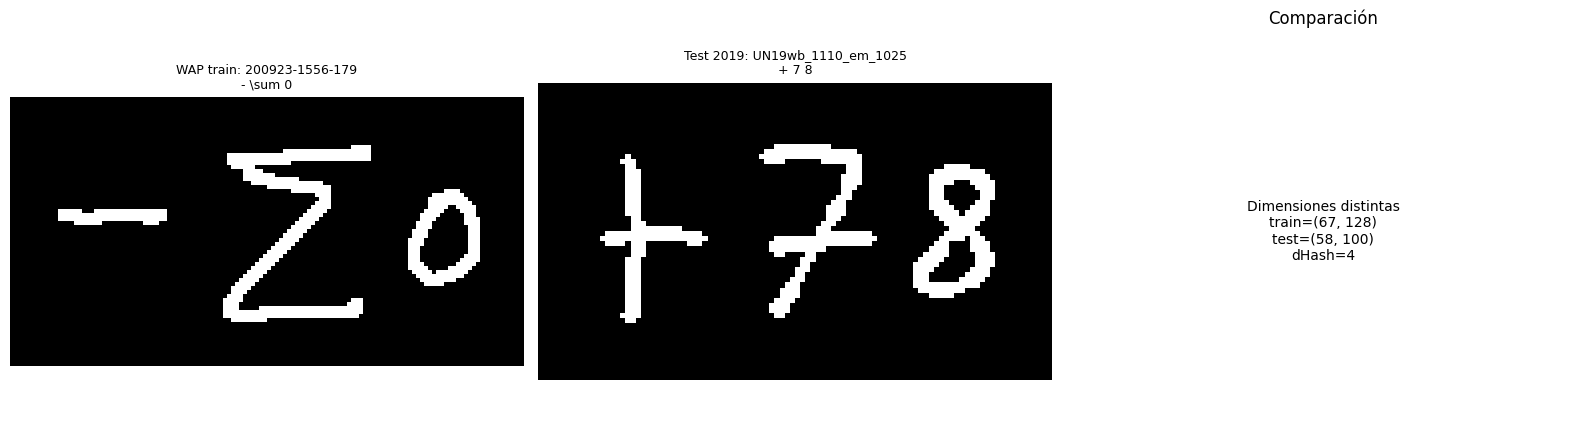

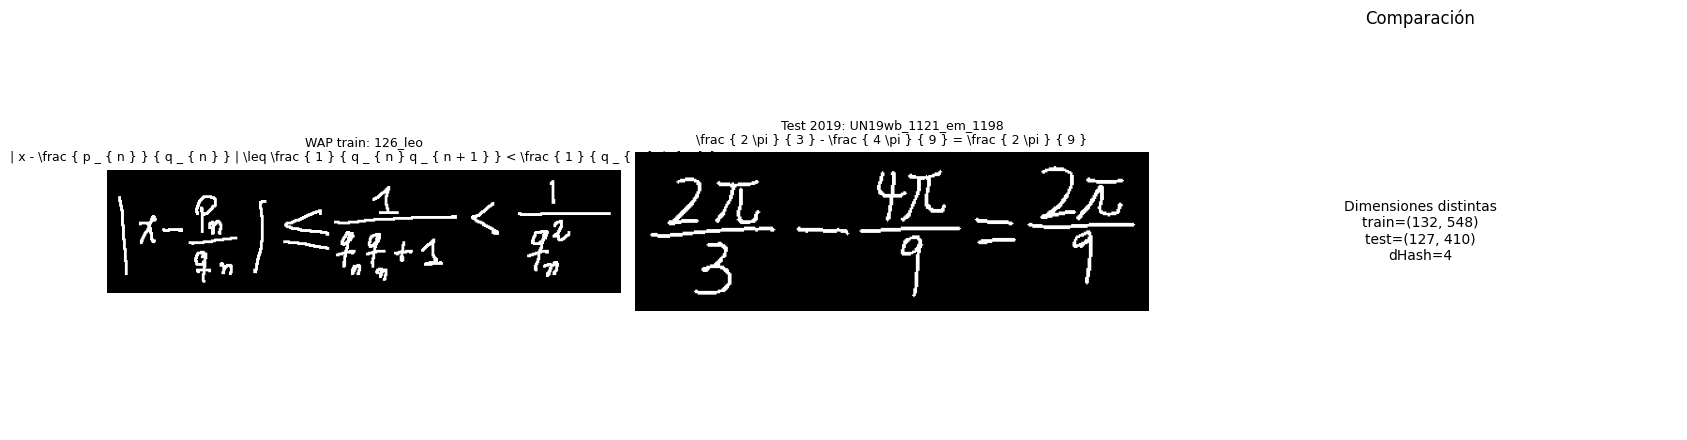

In [13]:
# Recupera una imagen WAP por su nombre interno.
def cargar_imagen_wap(miembro_tar):
    datos = leer_bytes_tar(WAP_TRAIN_TAR, miembro_tar)
    with Image.open(BytesIO(datos)) as imagen:
        return np.asarray(imagen.convert("L"))

def cargar_imagen_disco(ruta):
    with Image.open(ruta) as imagen:
        return np.asarray(imagen.convert("L"))

def mostrar_candidatos(candidatos, max_casos=MAX_CANDIDATOS_A_VISUALIZAR):
    if candidatos.empty:
        print("No hay candidatos perceptuales bajo el umbral.")
        return

    seleccion = candidatos.sort_values(
        ["distancia_hamming", "test", "id_test", "id_train"]
    ).head(max_casos)

    for _, caso in seleccion.iterrows():
        imagen_train = cargar_imagen_wap(caso["miembro_train"])
        imagen_test = cargar_imagen_disco(caso["imagen_test"])

        figura, ejes = plt.subplots(1, 3, figsize=(16, 4.5))
        ejes[0].imshow(imagen_train, cmap="gray", vmin=0, vmax=255)
        ejes[1].imshow(imagen_test, cmap="gray", vmin=0, vmax=255)

        ejes[0].set_title(
            f"WAP train: {caso['id_train']}\n{caso['latex_train']}",
            fontsize=9,
        )
        ejes[1].set_title(
            f"Test {caso['test']}: {caso['id_test']}\n{caso['latex_test']}",
            fontsize=9,
        )

        if imagen_train.shape == imagen_test.shape:
            diferencia = np.abs(
                imagen_train.astype(np.int16)
                - imagen_test.astype(np.int16)
            )
            ejes[2].imshow(diferencia, cmap="magma")
            ejes[2].set_title(
                f"Diferencia absoluta\n"
                f"dHash={caso['distancia_hamming']}, "
                f"píxeles exactos={caso['pixeles_exactos']}"
            )
        else:
            ejes[2].text(
                0.5,
                0.5,
                "Dimensiones distintas\n"
                f"train={imagen_train.shape}\n"
                f"test={imagen_test.shape}\n"
                f"dHash={caso['distancia_hamming']}",
                ha="center",
                va="center",
            )
            ejes[2].set_title("Comparación")

        for eje in ejes:
            eje.axis("off")
        figura.tight_layout()
        plt.show()

todos_candidatos = (
    pd.concat(candidatos_perceptuales.values(), ignore_index=True)
    if any(not tabla.empty for tabla in candidatos_perceptuales.values())
    else pd.DataFrame()
)
mostrar_candidatos(todos_candidatos)

## 14. Tabla de revisión manual

In [14]:
# Prepara una tabla editable sin decidir automáticamente los candidatos.
if todos_candidatos.empty:
    revision_manual = pd.DataFrame(
        columns=[
            "test", "id_train", "id_test", "distancia_hamming",
            "decision_visual", "observaciones",
        ]
    )
else:
    revision_manual = todos_candidatos[
        [
            "test", "id_train", "id_test", "distancia_hamming",
            "archivo_exacto", "pixeles_exactos",
            "latex_train", "latex_test",
        ]
    ].copy()
    revision_manual["decision_visual"] = "pendiente"
    revision_manual["observaciones"] = ""

display(revision_manual.head(100))

# Valores sugeridos:
# "misma instancia", "escrituras distintas", "falso positivo" o "ambiguo".

,test,id_train,id_test,distancia_hamming,archivo_exacto,pixeles_exactos,latex_train,latex_test,decision_visual,observaciones
0,2019,200923-1556-179,UN19wb_1110_em_1025,4,False,False,- \sum 0,+ 7 8,pendiente,
1,2019,126_leo,UN19wb_1121_em_1198,4,False,False,| x - \frac { p _ { n } } { q _ { n } } | \leq \frac { 1 } { q _ { n } q _ { n + 1 } } < \frac { 1 } { q _ { n } ^ { 2 } },\frac { 2 \pi } { 3 } - \frac { 4 \pi } { 9 } = \frac { 2 \pi } { 9 },pendiente,


## 15. Resumen de resultados

La conclusión principal se basa en ID, SHA-256 de archivo y SHA-256 de píxeles. dHash se informa por separado.

In [15]:
# Resume cada comparación sin mezclar evidencia exacta y aproximada.
filas_resumen = []

for nombre, test in objetivos.items():
    por_archivo = solapamientos_exactos[(nombre, "archivo")]
    por_pixeles = solapamientos_exactos[(nombre, "pixeles")]
    anio_candidatos = (
        "2016" if "2016" in nombre else "2019"
    )
    candidatos = candidatos_perceptuales.get(anio_candidatos, pd.DataFrame())

    filas_resumen.append(
        {
            "comparacion": f"wap_train vs. {nombre}",
            "muestras_test": len(test),
            "ids_compartidos": len(ids_compartidos[nombre]),
            "pares_archivo_exacto": len(por_archivo),
            "pares_pixeles_exactos": len(por_pixeles),
            "candidatos_perceptuales": (
                len(candidatos)
                if nombre.startswith("modelo2_")
                else pd.NA
            ),
        }
    )

df_resumen = pd.DataFrame(filas_resumen).set_index("comparacion")
display(df_resumen)

if (
    df_resumen["ids_compartidos"].sum() == 0
    and df_resumen["pares_archivo_exacto"].sum() == 0
    and df_resumen["pares_pixeles_exactos"].sum() == 0
):
    print(
        "No se detectaron solapamientos exactos por ID, archivo o píxeles. "
        "Revise por separado los candidatos perceptuales."
    )
else:
    print(
        "Se detectó al menos un solapamiento exacto. "
        "Revise las tablas antes de la evaluación final."
    )

,muestras_test,ids_compartidos,pares_archivo_exacto,pares_pixeles_exactos,candidatos_perceptuales
comparacion,,,,,
wap_train vs. wap_2016,1147,0,0,0,<NA>
wap_train vs. modelo2_2016,1147,0,0,0,0
wap_train vs. modelo2_2019,1199,0,0,0,2


No se detectaron solapamientos exactos por ID, archivo o píxeles. Revise por separado los candidatos perceptuales.


## 16. Exportación

Los resultados se guardan en `Cascada/00_analisis_exploratorio/resultados` cuando se ejecuta esta celda.

In [16]:
# Exporta resultados trazables sin modificar los datos originales.
RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)

resumen_hashes_wap.to_csv(
    RESULTADOS_DIR / "auditoria_wap_resumen_hashes.csv"
)
duplicados_wap_train.to_csv(
    RESULTADOS_DIR / "auditoria_wap_duplicados_train.csv",
    index=False,
)
comparacion_fuentes_2016.to_csv(
    RESULTADOS_DIR / "auditoria_wap_vs_modelo2_fuentes_2016.csv",
    index=False,
)
df_ground_truth.to_csv(
    RESULTADOS_DIR / "auditoria_wap_ground_truth_vs_2016_2019.csv"
)
df_resumen.to_csv(
    RESULTADOS_DIR / "auditoria_wap_solapamientos_resumen.csv"
)
revision_manual.to_csv(
    RESULTADOS_DIR / "auditoria_wap_revision_manual.csv",
    index=False,
)

for (nombre, tipo), tabla in solapamientos_exactos.items():
    tabla.to_csv(
        RESULTADOS_DIR
        / f"auditoria_wap_train_vs_{nombre}_{tipo}.csv",
        index=False,
    )

for anio, tabla in candidatos_perceptuales.items():
    tabla.to_csv(
        RESULTADOS_DIR
        / f"auditoria_wap_train_vs_{anio}_perceptual.csv",
        index=False,
    )

resumen_json = {
    "fuente": "data/WAP",
    "parametros_diagnosticos": {
        "umbral_hamming_dhash": UMBRAL_HAMMING_DHASH,
        "max_candidatos_por_imagen_test": MAX_CANDIDATOS_POR_IMAGEN_TEST,
        "semilla": SEMILLA,
    },
    "duplicados_internos_train": {
        clave: int(valor)
        for clave, valor in resumen_duplicados_wap.items()
    },
    "interpretacion": (
        "Los hashes exactos constituyen evidencia de identidad. "
        "Los candidatos perceptuales requieren revisión visual."
    ),
}

with (
    RESULTADOS_DIR / "auditoria_wap_resumen.json"
).open("w", encoding="utf-8") as archivo:
    json.dump(resumen_json, archivo, ensure_ascii=False, indent=2)

print(f"Resultados guardados en: {RESULTADOS_DIR}")

Resultados guardados en: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/00_analisis_exploratorio/resultados


## Guía de interpretación

- Menos hashes únicos que archivos indica duplicación interna.
- Mismo SHA-256 de archivo significa que los BMP son idénticos byte a byte.
- Mismo SHA-256 de píxeles significa que el raster y las dimensiones son idénticos, aunque el archivo se haya recodificado.
- dHash solo genera candidatos visuales y puede producir falsos positivos.
- Mismo *ground truth* no implica misma instancia.
- El test WAP 2016 y `Modelo2/2016` se contrastan para verificar si representan las mismas muestras bajo distintas preparaciones.
- La ausencia de coincidencias exactas permite afirmar que no se encontraron instancias idénticas bajo esos criterios, pero no demuestra la inexistencia absoluta de transformaciones profundas.
- Cualquier solapamiento detectado debe documentarse; no se debe eliminar ni alterar silenciosamente ningún dato.